# 09_discussion

This notebook summarises the final version 1.0 results from the nanoparticle diffusion project.

It compares theoretical and simulated diffusion coefficients for a range of particle radii, then shows the final figure generated in Notebook 08.

In [1]:
from pathlib import Path
import sys

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for path in [start, *start.parents]:
        if (path / "src").is_dir() and (path / "notebooks").is_dir():
            return path
    raise RuntimeError("Could not find project root containing src/ and notebooks/.")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")

Project root: C:\Users\study\Code\python-studies\nanoparticle-diffusion


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from src.constants import (
    DEFAULT_DT,
    DEFAULT_STEPS,
    DEFAULT_TEMPERATURE,
    DEFAULT_VISCOSITY,
)

from src.physics import (
    diffusion_coefficient,
    brownian_step_size,
)

from src.simulation import (
    simulate_population,
)

from src.analysis import (
    calculate_msd,
    estimate_diffusion,
)

In [3]:
def run_radius_experiment(
    radius_nm,
    particles=60,
    steps=600,
    dt=DEFAULT_DT,
    temperature=DEFAULT_TEMPERATURE,
    viscosity=DEFAULT_VISCOSITY,
    seed=42,
    fit_fraction=0.25,
):
    radius_m = radius_nm * 1e-9

    D_theoretical = diffusion_coefficient(
        temperature,
        viscosity,
        radius_m,
    )

    step_size = brownian_step_size(
        D_theoretical,
        dt,
    )

    np.random.seed(seed)

    x, y = simulate_population(
        particles,
        steps,
        step_size,
    )

    lag_times, msd = calculate_msd(
        x,
        y,
    )

    D_estimated, slope, intercept = estimate_diffusion(
        lag_times,
        msd,
        dt,
        fit_fraction=fit_fraction,
    )

    percent_error = abs(D_estimated - D_theoretical) / D_theoretical * 100

    return {
        "radius_nm": radius_nm,
        "D_theoretical": D_theoretical,
        "D_estimated": D_estimated,
        "percent_error": percent_error,
        "lag_times": lag_times,
        "msd": msd,
        "slope": slope,
        "intercept": intercept,
    }

In [4]:
radii_nm = [10, 50, 100, 200]

results = []

for radius_nm in radii_nm:
    result = run_radius_experiment(radius_nm)
    results.append(result)

print("Completed comparison experiment.")

Completed comparison experiment.


In [5]:
print(f"{'Radius (nm)':>12} {'Theory D (m^2/s)':>22} {'Sim D (m^2/s)':>22} {'% Error':>12}")

print("-" * 72)

for result in results:
    print(
        f"{result['radius_nm']:12.0f} "
        f"{result['D_theoretical']:22.3e} "
        f"{result['D_estimated']:22.3e} "
        f"{result['percent_error']:12.2f}"
    )

 Radius (nm)       Theory D (m^2/s)          Sim D (m^2/s)      % Error
------------------------------------------------------------------------
          10              2.271e-11              2.296e-11         1.14
          50              4.541e-12              4.593e-12         1.14
         100              2.271e-12              2.296e-12         1.14
         200              1.135e-12              1.148e-12         1.14


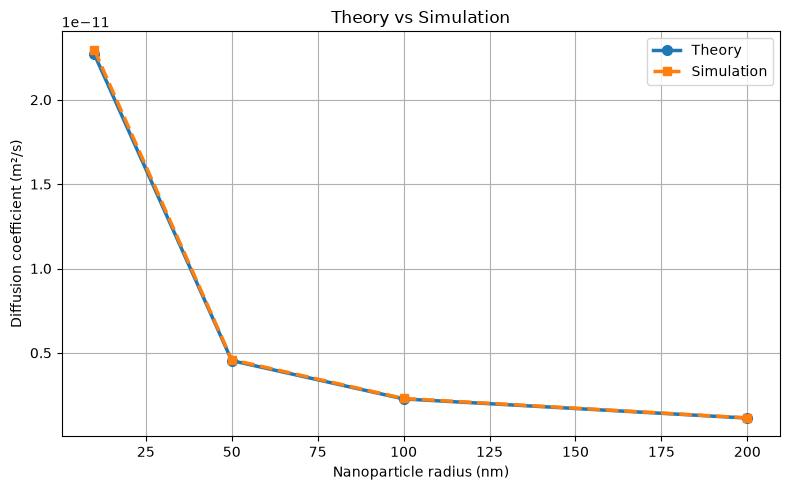

In [6]:
radii_plot = [r["radius_nm"] for r in results]
theory_plot = [r["D_theoretical"] for r in results]
sim_plot = [r["D_estimated"] for r in results]

plt.figure(figsize=(8,5))

plt.plot(
    radii_plot,
    theory_plot,
    "-o",
    linewidth=2.5,
    markersize=7,
    label="Theory",
)

plt.plot(
    radii_plot,
    sim_plot,
    "--s",
    linewidth=2.5,
    markersize=6,
    label="Simulation",
)

plt.xlabel("Nanoparticle radius (nm)")
plt.ylabel("Diffusion coefficient (m²/s)")
plt.title("Theory vs Simulation")
plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()

Looking for: C:\Users\study\Code\python-studies\nanoparticle-diffusion\figures\figure_radius_vs_diffusion.png


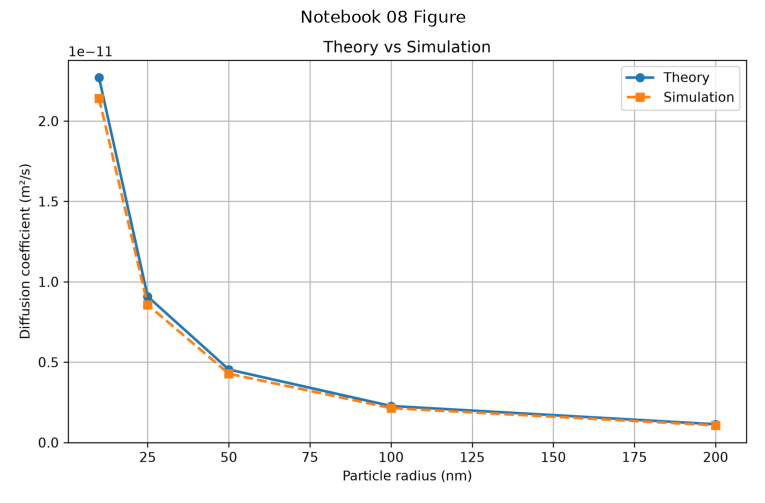

In [7]:
figure_path = PROJECT_ROOT / "figures" / "figure_radius_vs_diffusion.png"

print(f"Looking for: {figure_path}")

if figure_path.exists():

    img = plt.imread(figure_path)

    plt.figure(figsize=(10,6))
    plt.imshow(img)
    plt.axis("off")
    plt.title("Notebook 08 Figure")
    plt.show()

else:

    print("Figure not found.")

## Final Version 1.0 Summary

- Smaller nanoparticles diffuse faster.
- Higher temperature increases diffusion.
- The simulation follows the expected theoretical trend.
- The codebase is now split into reusable modules and notebooks.
- Version 1.0 is complete and ready for cleanup files, tests, and GitHub.

In [8]:
mean_error = np.mean([r["percent_error"] for r in results])

print("=" * 60)
print("PROJECT STATUS")
print("=" * 60)
print(f"Number of radii tested : {len(results)}")
print(f"Mean percentage error  : {mean_error:.2f}%")
print("Version                : 1.0")
print("Status                 : COMPLETE")

print("Version 1.0 discussion notebook complete.")

PROJECT STATUS
Number of radii tested : 4
Mean percentage error  : 1.14%
Version                : 1.0
Status                 : COMPLETE
Version 1.0 discussion notebook complete.
